# Phase 7 - Results Analysis

**Objective.** Bring the results of Phases 1 to 6 together, compare FD001 with FD002, and set out the evidence for each research question.

**Why this is needed.** Chapter 4 reports the results and Chapter 5 answers the research questions. Both need one consistent set of tables and figures.

This notebook only reads saved result files. No model is trained here and no number is typed by hand. Code: `src/results_summary.py` and `src/evaluation.py`.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import matplotlib.pyplot as plt

from src import evaluation as ev
from src import results_summary as rs

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.precision', 3)

saved = rs.run_all()   # thesis tables, Figure 8, reports/chapter4_tables_and_figures.md
print(len(saved), 'files written')

12 files written


## 1. Required visualisations

The eight visualisations in the thesis brief and the files that provide them.

In [2]:
rs.figure_inventory()

,required_visualisation,file,png,pdf,content
0,1. Dataset distribution,results/figures/fig01_dataset_distribution.png,True,True,"Trajectory lengths of training and test engines and true test RUL, FD001 and FD002."
1,2. Sensor trends over operating cycles,results/figures/fig02a_sensor_trends_FD001.png,True,True,All 21 sensors over the life of five FD001 training engines.
2,2. Sensor trends over operating cycles,results/figures/fig02b_operating_condition_effect.png,True,True,Four sensors for one engine in FD001 (one operating condition) and FD002 (six).
3,3. RUL degradation curves,results/figures/fig03a_rul_target.png,True,True,Linear RUL and the piecewise linear target capped at 125 cycles.
4,Supporting: preprocessing,results/figures/fig03b_normalisation_effect_FD002.png,True,True,One FD002 engine under dataset-wide and per-condition normalisation.
5,Supporting: feature representation,results/figures/fig03c_summary_features_example.png,True,True,"Raw readings, 30-cycle mean and 30-cycle standard deviation of sensor s11."
6,4. Actual vs predicted RUL,results/figures/fig04_actual_vs_predicted_summary.png,True,True,"Predicted against true RUL for every test engine, both models, three data configurations."
7,5. Random Forest vs XGBoost,results/figures/fig05_model_comparison.png,True,True,"Test RMSE, MAE and R2 with 95% bootstrap intervals."
8,6. Anomaly detection,results/figures/fig06a_anomaly_score_trajectories.png,True,True,"Anomaly score over the observed life of a test engine, with alarm threshold and refere..."
9,6. Anomaly detection,results/figures/fig06b_alarm_rate_by_rul.png,True,True,"Share of cycles flagged as remaining useful life falls, cross-validation and test."


## 2. Data and preprocessing

In [3]:
rs.table_datasets()

,subset,operating_conditions,fault_mode,split,engines,rows,min_cycles,mean_cycles,max_cycles
0,FD001,1,HPC degradation,train,100,20631,128,206.3,362
1,FD001,1,HPC degradation,test,100,13096,31,131.0,303
2,FD002,6,HPC degradation,train,260,53759,128,206.8,378
3,FD002,6,HPC degradation,test,259,33991,21,131.2,367


In [4]:
rs.table_preprocessing()

,data,sensors_retained,sensors_dropped,train_rows,train_rows_at_cap_percent,test_rows,test_engines,test_engines_true_rul_above_cap
0,FD001,15,"s1, s5, s10, s16, s18, s19",20631,39.4,13096,100,11
1,FD002 dataset-wide,21,none,53759,39.5,33991,259,57
2,FD002 per-condition,17,"s1, s5, s18, s19",53759,39.5,33991,259,57


FD001 and FD002 have the same fault mode and similar engine lifetimes. They differ in the number of operating conditions (one against six) and in size (100 against 260 training engines). 11 of 100 FD001 test engines and 57 of 259 FD002 test engines have a true RUL above the 125-cycle cap.

## 3. RUL prediction (Experiments 1 and 3)

In [5]:
rs.table_rul_results()

,data,representation,model,n_features,cv_rmse,test_mae,test_rmse,test_rmse_95ci,test_r2,test_mae_uncapped,test_rmse_uncapped,test_r2_uncapped
0,FD001,Raw sensors,Random Forest,15,18.54 +/- 0.73,11.828,16.856,13.68 to 19.82,0.823,12.898,17.864,0.815
1,FD001,Raw sensors,XGBoost,15,18.65 +/- 0.67,11.764,16.991,13.72 to 20.11,0.820,12.834,17.955,0.813
2,FD001,Summary statistics,Random Forest,45,17.32 +/- 0.60,11.907,16.409,13.48 to 19.35,0.832,12.977,17.535,0.822
3,FD001,Summary statistics,XGBoost,45,17.11 +/- 0.90,11.593,15.829,13.03 to 18.66,0.844,12.663,17.096,0.831
4,FD002 dataset-wide,Raw sensors,Random Forest,21,19.53 +/- 0.72,12.946,17.008,15.27 to 18.71,0.843,20.440,29.157,0.706
5,FD002 dataset-wide,Raw sensors,XGBoost,21,19.70 +/- 0.78,12.972,17.185,15.38 to 19.01,0.840,20.466,29.062,0.708
6,FD002 dataset-wide,Summary statistics,Random Forest,63,19.67 +/- 0.61,13.263,17.396,15.66 to 19.14,0.836,20.757,29.675,0.696
7,FD002 dataset-wide,Summary statistics,XGBoost,63,19.58 +/- 0.65,13.090,16.918,15.34 to 18.57,0.845,20.549,28.994,0.709
8,FD002 per-condition,Raw sensors,Random Forest,17,19.63 +/- 0.69,13.003,17.536,15.55 to 19.62,0.833,20.497,29.503,0.699
9,FD002 per-condition,Raw sensors,XGBoost,17,19.62 +/- 0.75,13.224,17.734,15.81 to 19.80,0.829,20.711,29.568,0.698


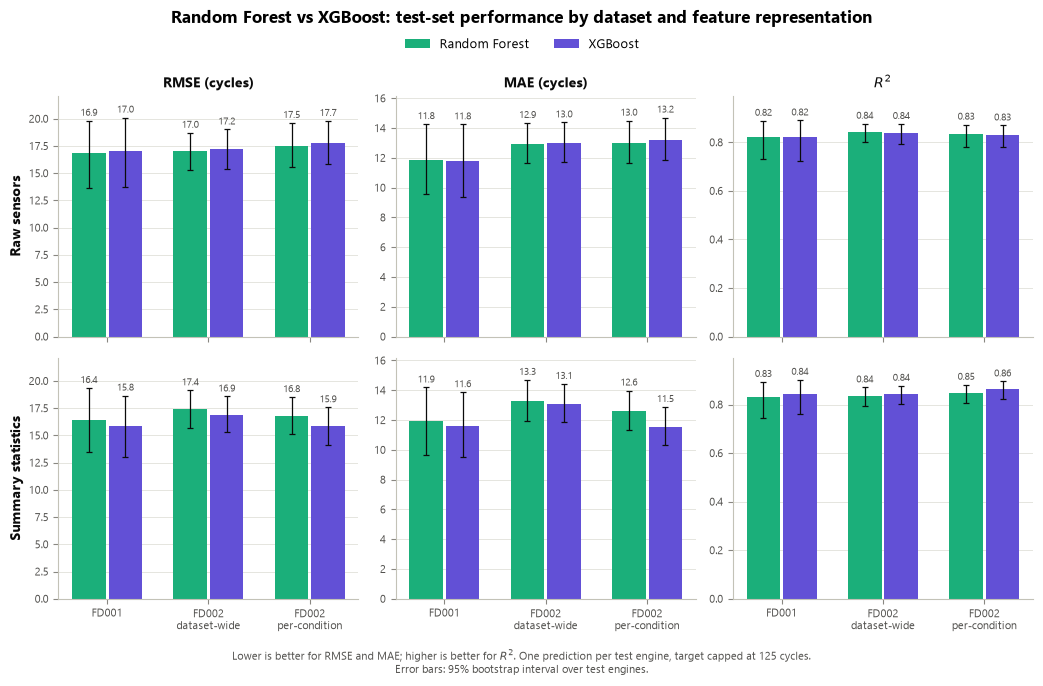

In [6]:
fig = ev.plot_model_comparison()
plt.show()

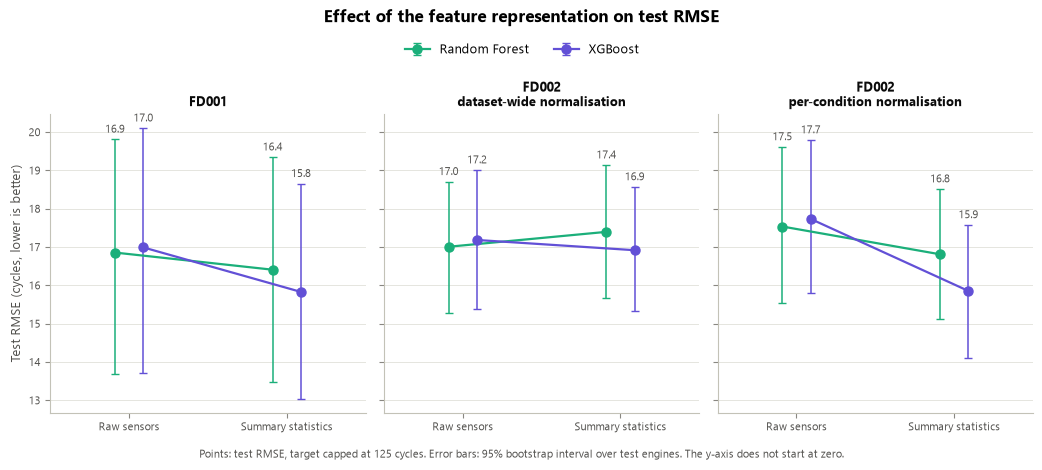

In [7]:
fig = ev.plot_representation_comparison()
plt.show()

In [8]:
diffs = rs.table_paired_differences()
summary = diffs.groupby('comparison', sort=False).agg(
    comparisons=('difference_B_minus_A', 'size'),
    smallest_difference=('difference_B_minus_A', 'min'),
    largest_difference=('difference_B_minus_A', 'max'),
    intervals_excluding_zero=('interval_excludes_zero', 'sum'))
summary

,comparisons,smallest_difference,largest_difference,intervals_excluding_zero
comparison,,,,
model,6,-0.957,0.198,1
representation,6,-1.880,0.388,1
normalisation,4,-1.063,0.549,0


**Reading the results.** With the capped target every configuration reaches a test RMSE between 15.8 and 17.7 cycles. The differences between models, feature representations and normalisation schemes are at most about 2 cycles, and 2 of the 16 paired intervals exclude zero.

## 4. Anomaly detection (Experiment 2)

In [9]:
rs.table_anomaly_results()

,data,representation,scoring,cv_precision,cv_recall,cv_f1,test_precision,test_recall,test_f1,cv_anomalous_percent,test_anomalous_percent
0,FD001,Raw sensors,all cycles,0.439,0.997,0.610,0.193,0.985,0.323,15.026,2.535
1,FD001,Summary statistics,all cycles,0.430,0.997,0.601,0.181,1.000,0.307,15.026,2.535
2,FD002 dataset-wide,Raw sensors,all cycles,0.491,0.797,0.607,0.199,0.747,0.315,14.993,3.198
3,FD002 dataset-wide,Summary statistics,all cycles,0.215,0.074,0.110,0.063,0.078,0.070,14.993,3.198
4,FD002 per-condition,Raw sensors,all cycles,0.466,0.978,0.631,0.196,0.959,0.325,14.993,3.198
5,FD002 per-condition,Summary statistics,all cycles,0.448,0.987,0.617,0.187,0.969,0.313,14.993,3.198
6,FD001,Raw sensors,healthy vs near failure,0.873,0.997,0.931,0.459,0.985,0.626,27.602,3.965
7,FD001,Summary statistics,healthy vs near failure,0.885,0.997,0.937,0.476,1.000,0.645,27.602,3.965
8,FD002 dataset-wide,Raw sensors,healthy vs near failure,0.853,0.797,0.824,0.463,0.747,0.572,27.491,4.989
9,FD002 dataset-wide,Summary statistics,healthy vs near failure,0.458,0.074,0.127,0.109,0.078,0.091,27.491,4.989


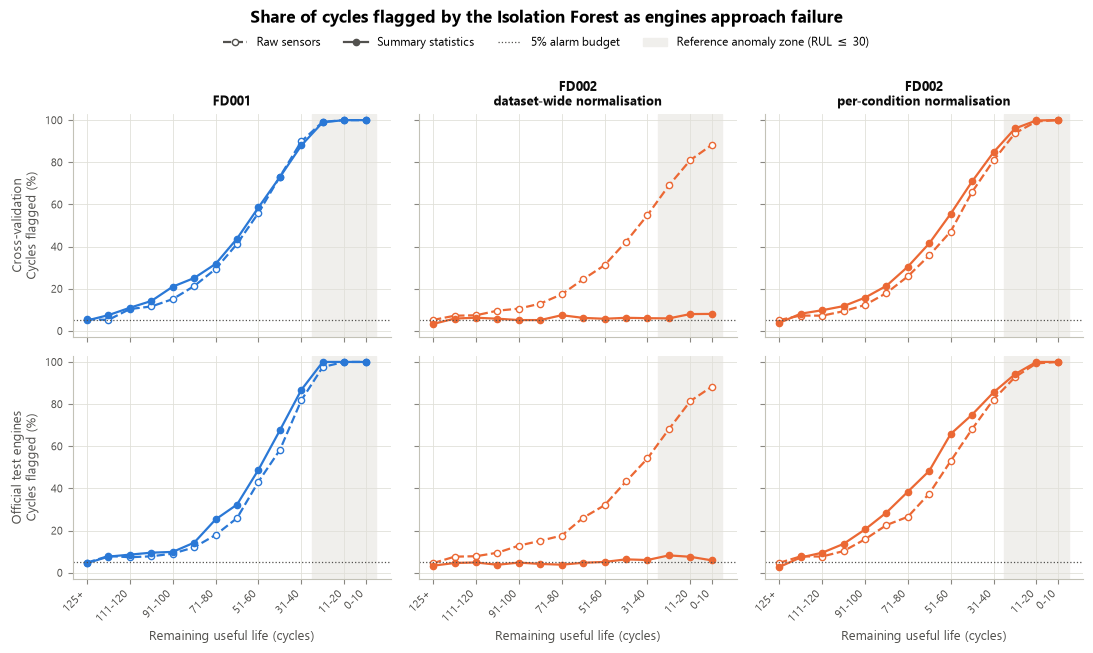

In [10]:
fig = ev.plot_alarm_rate_by_rul()
plt.show()

**Reading the results.** Where the normalisation suits the detector (FD001, and FD002 per condition) recall on the test engines is between 0.96 and 1.00. Precision against the 30-cycle label is about 0.19 because the share of flagged cycles rises gradually as engines degrade, well before 30 cycles remain.

## 5. FD001 vs FD002 (Figure 8)

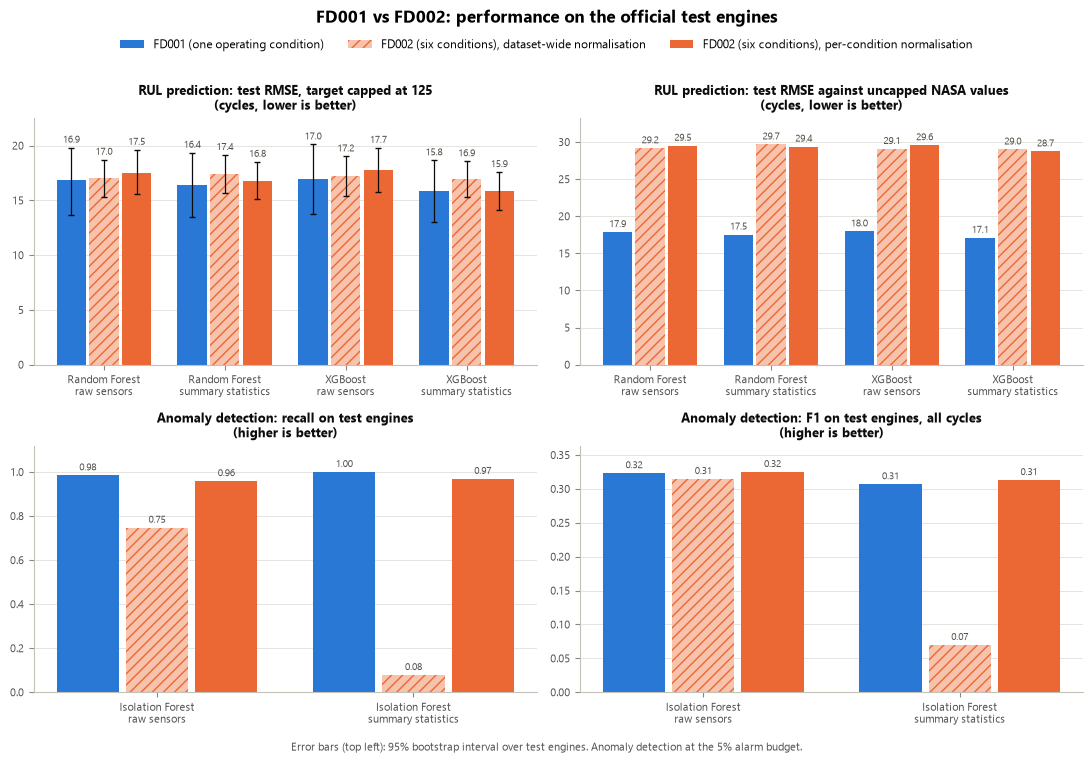

In [11]:
fig = rs.plot_dataset_comparison()
plt.show()

In [12]:
comparison = rs.table_dataset_comparison(with_intervals=False)
ranges = (comparison.groupby(['task', 'metric'], sort=False)
          [['FD001', 'FD002 dataset-wide', 'FD002 per-condition']].agg(['min', 'max']).round(2))
ranges

FD001         \
                                                      min    max   
task              metric                                           
RUL prediction    Test RMSE, capped target          15.83  16.99   
                  Test RMSE, uncapped target        17.10  17.95   
                  Test MAE, capped target           11.59  11.91   
                  Test R2, capped target             0.82   0.84   
                  Cross-validated RMSE              17.11  18.65   
Anomaly detection Test recall                        0.98   1.00   
                  Test precision, all cycles         0.18   0.19   
                  Test F1, all cycles                0.31   0.32   
                  Test F1, healthy vs near failure   0.63   0.64   

                                                   FD002 dataset-wide         \
                                                                  min    max   
task              metric                                                       
RUL prediction    Test RMSE, capped target                      16.92  17.40   
                  Test RMSE, uncapped target                    28.99  29.68   
                  Test MAE, capped target                       12.95  13.26   
                  Test R2, capped target                         0.84   0.84   
                  Cross-validated RMSE                          19.53  19.70   
Anomaly detection Test recall                                    0.08   0.75   
                  Test precision, all cycles                     0.06   0.20   
                  Test F1, all cycles                            0.07   0.31   
                  Test F1, healthy vs near failure               0.09   0.57   

                                                   FD002 per-condition         
                                                                   min    max  
task              metric                                                       
RUL prediction    Test RMSE, capped target                       15.85  17.73  
                  Test RMSE, uncapped target                     28.73  29.57  
                  Test MAE, capped target                        11.55  13.22  
                  Test R2, capped target                          0.83   0.86  
                  Cross-validated RMSE                           19.04  19.63  
Anomaly detection Test recall                                     0.96   0.97  
                  Test precision, all cycles                      0.19   0.20  
                  Test F1, all cycles                             0.31   0.32  
                  Test F1, healthy vs near failure                0.67   0.78

**Reading the figure and table.** The table gives the lowest and highest value of each metric across the model and feature combinations.

- *RUL, capped target.* FD001 and FD002 are close: test RMSE 15.8 to 17.0 on FD001 and 15.9 to 17.7 on FD002. Their intervals overlap widely.
- *RUL, uncapped target.* FD001 stays near 17 to 18 cycles but FD002 rises to about 29. This reflects the larger share of FD002 test engines with a true RUL above the cap (22% against 11%), which a model trained on a capped target cannot predict. It is a property of the evaluation convention and of the test sets, not evidence that six operating conditions make prediction harder.
- *RUL, cross-validation.* On all cycles of held-out training engines FD002 is 1 to 2.5 cycles worse than FD001 (19.0 to 19.7 against 17.1 to 18.7).
- *Anomaly detection.* FD002 comes close to FD001 only with per-condition normalisation (recall 0.96 to 0.97 against 0.985 to 1.00). With dataset-wide normalisation recall is 0.75 with raw sensors and 0.08 with summary statistics.

FD001 and FD002 differ in more than the number of operating conditions (FD002 has 2.6 times as many engines), so differences between them cannot be attributed to the operating conditions alone.

## 6. Evidence for the research questions

### RQ1 - How accurately can the selected models detect anomalies and predict RUL on single-condition and multi-condition data?

| Task | FD001 (single condition) | FD002 (multi-condition) |
|---|---|---|
| RUL, test RMSE, capped target | 15.8 to 17.0 cycles | 15.9 to 17.7 cycles |
| RUL, test MAE, capped target | 11.6 to 11.9 cycles | 11.5 to 13.3 cycles |
| RUL, test R2, capped target | 0.82 to 0.84 | 0.83 to 0.86 |
| RUL, test RMSE, uncapped target | 17.1 to 18.0 cycles | 28.7 to 29.7 cycles |
| Anomaly, test recall | 0.985 to 1.00 | 0.96 to 0.97 per-condition; 0.08 to 0.75 dataset-wide |
| Anomaly, test precision (all cycles) | 0.18 to 0.19 | 0.19 to 0.20 per-condition |
| Anomaly, test F1 (all cycles) | 0.31 to 0.32 | 0.31 to 0.33 per-condition |
| Anomaly, test F1 (healthy vs near failure) | 0.63 to 0.65 | 0.67 to 0.78 per-condition |

Random Forest and XGBoost perform alike; XGBoost is 0.5 to 1.0 cycles better with summary statistics. The Isolation Forest finds nearly all near-failure cycles but also flags many cycles in earlier stages of degradation.

### RQ2 - How do basic preprocessing techniques and feature representations affect performance?

| Factor | Supervised RUL models (test RMSE) | Unsupervised detector (test recall) |
|---|---|---|
| Per-condition instead of dataset-wide normalisation (FD002) | +0.5 cycles with raw sensors, -0.6 to -1.1 with summary statistics; all four intervals include zero | rises from 0.75 to 0.96 with raw sensors and from 0.08 to 0.97 with summary statistics |
| Summary statistics instead of raw sensors | -0.3 to -1.9 cycles in five of six cases, +0.4 in one; one interval excludes zero | Little change with suitable normalisation; failure with dataset-wide normalisation on FD002 |

The effect of preprocessing depends on the model. The supervised tree models are barely affected by the normalisation scheme. The unsupervised detector depends on it.

*Theoretical expectation, not tested here:* any rescaling applied to a whole column (min-max or z-score over the dataset) leaves the order of values unchanged, so tree-based models make the same splits with or without it. Only per-condition normalisation can change their results.

### Limits on these conclusions

- C-MAPSS is a simulation. The results do not show how the models would perform on real engines.
- One random seed and one official train/test split were used.
- The anomaly reference label (30 cycles) and the alarm budget (5%) are choices; other values give other precision and recall figures.
- Sixteen paired comparisons were made without correction for multiple comparisons.
- No uncertainty intervals were computed for the anomaly detection scores.